## PROJECT TITLE: Health Insurance Customers Data Analysis

### Project Goals

The main goal of this project is to perform Exploratory Data Analysis (EDA) on health insurance customer data to identify meaningful patterns, trends, and insights.

1. **Exploratory Data Analysis (EDA):** Explore the health insurance dataset to understand its structure, characteristics, and patterns.

2. **Customer and Policy-Wise Analysis:** Analyze customer information and insurance policy details to understand customer profiles and policy distribution.

3. **Statistical Analysis:** Apply statistical methods to summarize customer demographics, insurance coverage, hospital expenses, and claim amounts.

4. **Data Visualization:** Use Matplotlib and Seaborn to create charts and graphs for clear and effective data presentation.

5. **Customer Demographic Analysis:** Analyze customers based on age, gender, location, occupation, and other demographic characteristics.

6. **Policy and Coverage Analysis:** Examine policy types, sum insured, and available policy-related information to understand coverage patterns.

7. **Claim Analysis:** Analyze claim amounts, claim-related information, and claim frequency to identify trends in insurance claims.

8. **Insight Generation:** Generate meaningful insights from the data to support better understanding of customer behavior, insurance coverage, healthcare expenses, and claim patterns.

## Project Objectives

Understand the structure and characteristics of the health insurance dataset.

Identify and handle duplicate records and missing values appropriately.

Analyze customer demographics, including age, gender, and location where available.

Examine policy details, premiums, and coverage information.

Explore claim amounts, claim status, and other claim-related variables.

Use descriptive statistics and data visualizations to identify patterns and outliers.

Generate meaningful insights from the available health insurance data.

In [103]:
# ==============================================================================
# IMPORT LIBRARIES & ENVIRONMENT SETUP
# ==============================================================================

# Data manipulation and analysis
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Interactive visualizations
import plotly.express as px

# Report formatting
from tabulate import tabulate

# Configure pandas options for display
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 1000)

print("Libraries imported and environment configured successfully!")

Libraries imported and environment configured successfully!


In [104]:
# ==============================================================================
# GOOGLE COLAB DRIVE MOUNT
# ==============================================================================

from google.colab import drive
drive.mount('/content/drive')

print("Google Drive mounted successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive mounted successfully!


In [ ]:
df = pd.read_csv("/content/Health Insurance Customers Data Analysis.csv")

> ### 📊 Dataset Description Summary
>
> * **Dataset Name:** Health Insurance Customer Dataset
> * **Source:** Google Colab Drive Link
> * **Initial Records:** 8,000 rows
> * **Total Columns:** 38
>     * 🔹 *Float Columns:* 9
>     * 🔹 *Integer Columns:* 7
>     * 🔹 *Object Columns:* 22
> * **Duplicate Records Removed:** 5
> * **Final Records:** 7,995 rows


## Features List – Health Insurance Customer Dataset

1. Data loading and initial inspection of the dataset.
2. Data cleaning, including handling missing values, duplicate records, and inconsistent values.
3. Data type conversion and preprocessing.
4. Outlier detection and investigation using the IQR method.
5. Exploratory Data Analysis (EDA) using summary statistics.
6. Customer demographic analysis based on age, gender, and location.
7. Health condition analysis based on BMI, diabetes, hypertension, and other available health indicators.
8. Customer income and financial profile analysis.
9. Insurance policy-wise analysis.
10. Premium and coverage amount analysis.
11. Policy start date and claim date analysis.
12. Claim amount and claim status analysis.
13. Hospital bill amount and total claim amount analysis.
14. Hospitalization analysis based on ICU days and length of stay.
15. Statistical analysis of numerical variables.
16. Correlation analysis between relevant numerical variables.
17. Data visualization using Matplotlib and Seaborn.
18. Comparison of customer demographics, policy details, and claim trends.
19. Analysis of relationships between customer health conditions, insurance claims, hospital expenses, and other relevant variables.
20. Identification and investigation of unusual values and potential data quality issues.
21. Identification of key insights, patterns, and findings from the analysis.

In [106]:
df

,policy_id,customer_name,gender,age,marital_status,state,city,pincode,aadhaar_masked,occupation_type,annual_income_inr,bmi,tobacco_usage,alcohol_units_per_week,physical_activity_level,diet_type,has_diabetes,has_hypertension,family_history_cardiac,stress_level_score,policy_type,sum_insured,policy_start_date,claim_date,hospital_name,hospital_tier,room_category,icu_days,length_of_stay,cashless_claim,agent_channel,hospital_bill_amount,pre_hospitalization_expense,post_hospitalization_expense,non_payable_items,deductible_amount,co_pay_amount,total_claim_amount
0,IND103304,Alka Mukhopadhyay,F,36,Divorced,Tamil Nadu,Chennai,847016,XXXX-XXXX-6575,Business,823300.22,28.779126,smoking,4,low,non-veg,0.0,0.0,0,NaN,individual,2000000,13-09-2019,23-04-2022,"Lall, Bumb and Dua Hospital",private_small,general,2,6,yes,online,160039.77,15092.716960,14816.007640,5229.900734,6634.961901,26405.574580,"â‚¹151,678"
1,IND101987,Gautami Chanda,F,39,married,Karnataka,Bengaluru,432335,XXXX-XXXX-2872,Retired,989128.77,30.729990,none,2,low,veg,0.0,1.0,0,4.751607,individual,2000000,11-12-2021,04-11-2023,"Rai, Randhawa and Ray Hospital",private_small,deluxe,3,6,no,bancassurance,173704.83,14920.655850,10384.480860,12756.023430,6987.996116,16771.482340,162494.46
2,IND104725,Ridhi Wable,Male,48,married,Karnataka,Bengaluru,807064,XXXX-XXXX-9125,Self-employed,717704.79,28.208313,smoking,0,moderate,vegan,0.0,0.0,1,4.786732,family_floater,500000,20-05-2021,20-03-2023,Kadakia PLC Hospital,private_corporate,semi-private,3,5,yes,agent,220261.47,16202.882190,19974.634740,9624.570612,10524.495690,31255.241300,205034.68
3,IND105031,Ethan Shankar,M,46,Widowed,Tamil Nadu,Coimbatore,900329,XXXX-XXXX-1493,Self-employed,795085.69,20.424576,chewing,4,low,non-veg,0.0,0.0,0,7.677186,family_floater,2000000,11-05-2020,06-09-2021,Apte-Dhawan Hospital,private_corporate,private,0,5,no,aggregator,128736.67,9340.872259,6760.021670,2622.298761,6400.820348,21994.193710,512986.56
4,IND107599,Logan Chaudhry,F,18,Married,Tamil Nadu,Chennai,466064,2.86274E+11,Unemployed,501550.91,31.507076,none,4,low,veg,0.0,0.0,0,4.002162,individual,1000000,26-04-2021,25-07-2024,"Shan, Rao and Sekhon Hospital",private_corporate,private,2,5,yes,aggregator,148014.44,16595.311360,17123.418400,11346.864180,1550.856123,21866.765760,"â‚¹146,969"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7995,IND106980,Reyansh Rana,M,48,Single,Uttar Pradesh,Noida,190127,XXXX-XXXX-2594,Business,694172.6,29.957491,none,6,moderate,eggetarian,0.0,0.0,1,1.000000,senior_citizen,300000,10-07-2018,03-12-2020,"Ganguly, Bal and Sane Hospital",private_corporate,deluxe,1,3,yes,bancassurance,112095.51,9773.960513,7155.756557,6399.783427,2372.806301,9271.059721,110981.57
7996,IND103380,Vinaya Misra,M,30,Widowed,Maharashtra,Mumbai,345012,XXXX-XXXX-5959,Student,1067483.14,16.964565,none,6,moderate,non-veg,0.0,0.0,1,7.950987,family_floater,1000000,11-11-2020,13-06-2022,Rana Group Hospital,private_corporate,general,2,7,yes,agent,143721.77,16665.583940,12761.009050,11048.995970,4262.727496,8314.589584,149522.05
7997,IND105734,Chaitaly Taneja,Male,70,Single,West Bengal,Kolkata,526383,XXXX-XXXX-5759,Student,569677.07,33.894353,none,3,high,eggetarian,0.0,0.0,0,1.641074,individual,500000,09-12-2023,24-12-2027,Sinha-Kala Hospital,govt,deluxe,1,1,no,online,38333.94,3049.369421,3316.069688,2571.019786,1367.759796,4998.287457,"35,762"
7998,IND107279,Christopher Sur,Female,29,Single,Tamil Nadu,Chennai,697145,XXXX-XXXX-5878,Salaried,NaN,22.375727,none,5,low,eggetarian,0.0,0.0,0,5.109872,individual,1000000,06-08-2022,12-05-2024,"Ram, Mann and Nigam Hospital",private_corporate,private,1,2,yes,agent,82792.92,7945.909620,7765.790618,2841.099120,2643.875743,14553.928350,78465.72


In [107]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 38 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   policy_id                     8000 non-null   object 
 1   customer_name                 8000 non-null   object 
 2   gender                        8000 non-null   object 
 3   age                           8000 non-null   int64  
 4   marital_status                8000 non-null   object 
 5   state                         8000 non-null   object 
 6   city                          8000 non-null   object 
 7   pincode                       8000 non-null   int64  
 8   aadhaar_masked                8000 non-null   object 
 9   occupation_type               8000 non-null   object 
 10  annual_income_inr             7437 non-null   object 
 11  bmi                           7440 non-null   float64
 12  tobacco_usage                 8000 non-null   object 
 13  alc

In [108]:
df.head()

,policy_id,customer_name,gender,age,marital_status,state,city,pincode,aadhaar_masked,occupation_type,annual_income_inr,bmi,tobacco_usage,alcohol_units_per_week,physical_activity_level,diet_type,has_diabetes,has_hypertension,family_history_cardiac,stress_level_score,policy_type,sum_insured,policy_start_date,claim_date,hospital_name,hospital_tier,room_category,icu_days,length_of_stay,cashless_claim,agent_channel,hospital_bill_amount,pre_hospitalization_expense,post_hospitalization_expense,non_payable_items,deductible_amount,co_pay_amount,total_claim_amount
0,IND103304,Alka Mukhopadhyay,F,36,Divorced,Tamil Nadu,Chennai,847016,XXXX-XXXX-6575,Business,823300.22,28.779126,smoking,4,low,non-veg,0.0,0.0,0,NaN,individual,2000000,13-09-2019,23-04-2022,"Lall, Bumb and Dua Hospital",private_small,general,2,6,yes,online,160039.77,15092.716960,14816.00764,5229.900734,6634.961901,26405.57458,"â‚¹151,678"
1,IND101987,Gautami Chanda,F,39,married,Karnataka,Bengaluru,432335,XXXX-XXXX-2872,Retired,989128.77,30.729990,none,2,low,veg,0.0,1.0,0,4.751607,individual,2000000,11-12-2021,04-11-2023,"Rai, Randhawa and Ray Hospital",private_small,deluxe,3,6,no,bancassurance,173704.83,14920.655850,10384.48086,12756.023430,6987.996116,16771.48234,162494.46
2,IND104725,Ridhi Wable,Male,48,married,Karnataka,Bengaluru,807064,XXXX-XXXX-9125,Self-employed,717704.79,28.208313,smoking,0,moderate,vegan,0.0,0.0,1,4.786732,family_floater,500000,20-05-2021,20-03-2023,Kadakia PLC Hospital,private_corporate,semi-private,3,5,yes,agent,220261.47,16202.882190,19974.63474,9624.570612,10524.495690,31255.24130,205034.68
3,IND105031,Ethan Shankar,M,46,Widowed,Tamil Nadu,Coimbatore,900329,XXXX-XXXX-1493,Self-employed,795085.69,20.424576,chewing,4,low,non-veg,0.0,0.0,0,7.677186,family_floater,2000000,11-05-2020,06-09-2021,Apte-Dhawan Hospital,private_corporate,private,0,5,no,aggregator,128736.67,9340.872259,6760.02167,2622.298761,6400.820348,21994.19371,512986.56
4,IND107599,Logan Chaudhry,F,18,Married,Tamil Nadu,Chennai,466064,2.86274E+11,Unemployed,501550.91,31.507076,none,4,low,veg,0.0,0.0,0,4.002162,individual,1000000,26-04-2021,25-07-2024,"Shan, Rao and Sekhon Hospital",private_corporate,private,2,5,yes,aggregator,148014.44,16595.311360,17123.41840,11346.864180,1550.856123,21866.76576,"â‚¹146,969"


In [109]:
df.tail()

,policy_id,customer_name,gender,age,marital_status,state,city,pincode,aadhaar_masked,occupation_type,annual_income_inr,bmi,tobacco_usage,alcohol_units_per_week,physical_activity_level,diet_type,has_diabetes,has_hypertension,family_history_cardiac,stress_level_score,policy_type,sum_insured,policy_start_date,claim_date,hospital_name,hospital_tier,room_category,icu_days,length_of_stay,cashless_claim,agent_channel,hospital_bill_amount,pre_hospitalization_expense,post_hospitalization_expense,non_payable_items,deductible_amount,co_pay_amount,total_claim_amount
7995,IND106980,Reyansh Rana,M,48,Single,Uttar Pradesh,Noida,190127,XXXX-XXXX-2594,Business,694172.6,29.957491,none,6,moderate,eggetarian,0.0,0.0,1,1.000000,senior_citizen,300000,10-07-2018,03-12-2020,"Ganguly, Bal and Sane Hospital",private_corporate,deluxe,1,3,yes,bancassurance,112095.51,9773.960513,7155.756557,6399.783427,2372.806301,9271.059721,110981.57
7996,IND103380,Vinaya Misra,M,30,Widowed,Maharashtra,Mumbai,345012,XXXX-XXXX-5959,Student,1067483.14,16.964565,none,6,moderate,non-veg,0.0,0.0,1,7.950987,family_floater,1000000,11-11-2020,13-06-2022,Rana Group Hospital,private_corporate,general,2,7,yes,agent,143721.77,16665.583940,12761.009050,11048.995970,4262.727496,8314.589584,149522.05
7997,IND105734,Chaitaly Taneja,Male,70,Single,West Bengal,Kolkata,526383,XXXX-XXXX-5759,Student,569677.07,33.894353,none,3,high,eggetarian,0.0,0.0,0,1.641074,individual,500000,09-12-2023,24-12-2027,Sinha-Kala Hospital,govt,deluxe,1,1,no,online,38333.94,3049.369421,3316.069688,2571.019786,1367.759796,4998.287457,"35,762"
7998,IND107279,Christopher Sur,Female,29,Single,Tamil Nadu,Chennai,697145,XXXX-XXXX-5878,Salaried,NaN,22.375727,none,5,low,eggetarian,0.0,0.0,0,5.109872,individual,1000000,06-08-2022,12-05-2024,"Ram, Mann and Nigam Hospital",private_corporate,private,1,2,yes,agent,82792.92,7945.909620,7765.790618,2841.099120,2643.875743,14553.928350,78465.72
7999,IND103780,Lopa Divan,F,18,married,Delhi,New Delhi,283061,XXXX-XXXX-6600,Salaried,10.2 LPA,20.760707,both,0,low,veg,0.0,0.0,0,4.903981,family_floater,5000000,14-11-2021,23-04-2026,Nadkarni-Bava Hospital,private_small,private,1,5,yes,agent,"â‚¹112,619",9320.484364,12530.399950,3302.533186,1741.264897,7748.794821,121676.82


In [110]:
df.shape

(8000, 38)

In [111]:
df.columns

Index(['policy_id', 'customer_name', 'gender', 'age', 'marital_status', 'state', 'city', 'pincode', 'aadhaar_masked', 'occupation_type', 'annual_income_inr', 'bmi', 'tobacco_usage', 'alcohol_units_per_week', 'physical_activity_level', 'diet_type', 'has_diabetes', 'has_hypertension', 'family_history_cardiac', 'stress_level_score', 'policy_type', 'sum_insured', 'policy_start_date', 'claim_date', 'hospital_name', 'hospital_tier', 'room_category', 'icu_days', 'length_of_stay', 'cashless_claim', 'agent_channel', 'hospital_bill_amount', 'pre_hospitalization_expense', 'post_hospitalization_expense', 'non_payable_items', 'deductible_amount', 'co_pay_amount', 'total_claim_amount'], dtype='object')

In [112]:
df.dtypes

,0
policy_id,object
customer_name,object
gender,object
age,int64
marital_status,object
state,object
city,object
pincode,int64
aadhaar_masked,object
occupation_type,object


In [113]:
df.describe()

,age,pincode,bmi,alcohol_units_per_week,has_diabetes,has_hypertension,family_history_cardiac,stress_level_score,sum_insured,icu_days,length_of_stay,pre_hospitalization_expense,post_hospitalization_expense,non_payable_items,deductible_amount,co_pay_amount
count,8000.000000,8000.000000,7440.000000,8000.000000,7617.000000,7609.000000,8000.000000,7440.000000,8.000000e+03,8000.000000,8000.000000,8000.000000,7999.000000,8000.000000,8000.000000,7998.000000
mean,41.754375,541746.620875,25.989566,3.002500,0.216489,0.266001,0.340375,5.035093,1.747825e+06,0.997375,3.987375,12067.342553,10317.466493,6108.970237,3642.421882,15359.568759
std,15.105208,264461.419025,4.904692,1.732662,0.411879,0.441894,0.473865,1.939680,1.715841e+06,0.996239,2.002553,6647.592654,5482.133979,3628.568696,2263.099848,9163.456460
min,18.000000,13587.000000,15.000000,0.000000,0.000000,0.000000,0.000000,1.000000,3.000000e+05,0.000000,0.000000,-1842.506228,-1669.771508,-1260.602175,-499.309969,-2253.341868
25%,30.000000,310077.750000,22.537105,2.000000,0.000000,0.000000,0.000000,3.687867,5.000000e+05,0.000000,3.000000,7237.764156,6371.252371,3418.922128,1935.514955,8640.143438
50%,41.000000,538988.000000,25.996548,3.000000,0.000000,0.000000,0.000000,5.032164,1.000000e+06,1.000000,4.000000,10855.140130,9327.568942,5364.667947,3149.775814,13455.742945
75%,52.000000,773316.000000,29.330098,4.000000,0.000000,1.000000,1.000000,6.383080,2.000000e+06,2.000000,5.000000,15567.766658,13185.385360,8012.995459,4839.563036,20187.029067
max,85.000000,999797.000000,43.682658,11.000000,1.000000,1.000000,1.000000,10.000000,5.000000e+06,6.000000,13.000000,55993.747130,43600.021950,27252.866180,18921.640280,73377.223460


In [114]:
df.isnull().sum()

,0
policy_id,0
customer_name,0
gender,0
age,0
marital_status,0
state,0
city,0
pincode,0
aadhaar_masked,0
occupation_type,0


In [115]:
df.duplicated().sum()

np.int64(5)

### Data Cleaning

1. Checking the dataset structure, column names, and data types.
2. Identifying missing values in each column.
3. Detecting duplicate records.
4. Converting columns to appropriate data types.
5. Converting date columns into the correct date format.
6. Correcting inconsistent values in categorical columns.
7. Cleaning numerical columns and handling invalid values.
8. Checking for invalid values in age, BMI, income, and medical expenses.
9. Validating policy start dates and claim dates.
10. Checking consistency between ICU days and hospital length of stay.
11. Handling missing values using appropriate methods.
12. Removing duplicate records.
13. Detecting and investigating outliers using the IQR method.
14. Verifying data quality after cleaning.
15. Performing final checks for missing values and duplicates.
16. Preparing the cleaned dataset for Exploratory Data Analysis (EDA).

## Step 1: Checking dataset structure, column names, and data types

In [116]:
# Step 1: Initial dataset inspection

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nData Types:")
display(df.dtypes.to_frame(name="Data Type"))

Dataset Shape: (8000, 38)

Column Names:
['policy_id', 'customer_name', 'gender', 'age', 'marital_status', 'state', 'city', 'pincode', 'aadhaar_masked', 'occupation_type', 'annual_income_inr', 'bmi', 'tobacco_usage', 'alcohol_units_per_week', 'physical_activity_level', 'diet_type', 'has_diabetes', 'has_hypertension', 'family_history_cardiac', 'stress_level_score', 'policy_type', 'sum_insured', 'policy_start_date', 'claim_date', 'hospital_name', 'hospital_tier', 'room_category', 'icu_days', 'length_of_stay', 'cashless_claim', 'agent_channel', 'hospital_bill_amount', 'pre_hospitalization_expense', 'post_hospitalization_expense', 'non_payable_items', 'deductible_amount', 'co_pay_amount', 'total_claim_amount']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 38 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   policy_id                     80

,Data Type
policy_id,object
customer_name,object
gender,object
age,int64
marital_status,object
state,object
city,object
pincode,int64
aadhaar_masked,object
occupation_type,object


## Step 2: Identifying missing values in each column

In [117]:
# Step 2: Check missing values

missing_report = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing_report.sort_values(
    by="Missing Values", ascending=False
))

print("Total Missing Values:", df.isnull().sum().sum())

,Missing Values,Missing Percentage
annual_income_inr,563,7.04
bmi,560,7.00
stress_level_score,560,7.00
has_hypertension,391,4.89
has_diabetes,383,4.79
co_pay_amount,2,0.02
agent_channel,1,0.01
post_hospitalization_expense,1,0.01
state,0,0.00
marital_status,0,0.00


Total Missing Values: 2461


# Step 3: Detecting duplicate records

In [118]:

# 3. Check duplicate records before removal

print("Duplicate Records:", df.duplicated().sum())

# Display duplicate rows for inspection
display(df[df.duplicated(keep=False)].head(10))


Duplicate Records: 5


,policy_id,customer_name,gender,age,marital_status,state,city,pincode,aadhaar_masked,occupation_type,annual_income_inr,bmi,tobacco_usage,alcohol_units_per_week,physical_activity_level,diet_type,has_diabetes,has_hypertension,family_history_cardiac,stress_level_score,policy_type,sum_insured,policy_start_date,claim_date,hospital_name,hospital_tier,room_category,icu_days,length_of_stay,cashless_claim,agent_channel,hospital_bill_amount,pre_hospitalization_expense,post_hospitalization_expense,non_payable_items,deductible_amount,co_pay_amount,total_claim_amount
10,IND107279,Christopher Sur,Female,29,Single,Tamil Nadu,Chennai,697145,XXXX-XXXX-5878,Salaried,NaN,22.375727,none,5,low,eggetarian,0.0,0.0,0,5.109872,individual,1000000,06-08-2022,12-05-2024,"Ram, Mann and Nigam Hospital",private_corporate,private,1,2,yes,agent,82792.92,7945.909620,7765.790618,2841.099120,2643.875743,14553.928350,78465.72
627,IND102340,Nakul Raghavan,male,18,Divorced,West Bengal,Kolkata,715354,XXXX-XXXX-1148,Self-employed,948803.41,26.540601,smoking,1,high,eggetarian,0.0,0.0,0,5.905461,individual,5000000,27-11-2019,12-07-2022,Sidhu Ltd Hospital,private_small,deluxe,0,2,yes,bancassurance,53122.25,7850.177604,5489.951830,1931.815846,2079.684592,3231.938396,59218.94
7291,IND107279,Christopher Sur,Female,29,Single,Tamil Nadu,Chennai,697145,XXXX-XXXX-5878,Salaried,NaN,22.375727,none,5,low,eggetarian,0.0,0.0,0,5.109872,individual,1000000,06-08-2022,12-05-2024,"Ram, Mann and Nigam Hospital",private_corporate,private,1,2,yes,agent,82792.92,7945.909620,7765.790618,2841.099120,2643.875743,14553.928350,78465.72
7296,IND107279,Christopher Sur,Female,29,Single,Tamil Nadu,Chennai,697145,XXXX-XXXX-5878,Salaried,NaN,22.375727,none,5,low,eggetarian,0.0,0.0,0,5.109872,individual,1000000,06-08-2022,12-05-2024,"Ram, Mann and Nigam Hospital",private_corporate,private,1,2,yes,agent,82792.92,7945.909620,7765.790618,2841.099120,2643.875743,14553.928350,78465.72
7983,IND102340,Nakul Raghavan,male,18,Divorced,West Bengal,Kolkata,715354,XXXX-XXXX-1148,Self-employed,948803.41,26.540601,smoking,1,high,eggetarian,0.0,0.0,0,5.905461,individual,5000000,27-11-2019,12-07-2022,Sidhu Ltd Hospital,private_small,deluxe,0,2,yes,bancassurance,53122.25,7850.177604,5489.951830,1931.815846,2079.684592,3231.938396,59218.94
7989,IND102340,Nakul Raghavan,male,18,Divorced,West Bengal,Kolkata,715354,XXXX-XXXX-1148,Self-employed,948803.41,26.540601,smoking,1,high,eggetarian,0.0,0.0,0,5.905461,individual,5000000,27-11-2019,12-07-2022,Sidhu Ltd Hospital,private_small,deluxe,0,2,yes,bancassurance,53122.25,7850.177604,5489.951830,1931.815846,2079.684592,3231.938396,59218.94
7998,IND107279,Christopher Sur,Female,29,Single,Tamil Nadu,Chennai,697145,XXXX-XXXX-5878,Salaried,NaN,22.375727,none,5,low,eggetarian,0.0,0.0,0,5.109872,individual,1000000,06-08-2022,12-05-2024,"Ram, Mann and Nigam Hospital",private_corporate,private,1,2,yes,agent,82792.92,7945.909620,7765.790618,2841.099120,2643.875743,14553.928350,78465.72


## Step 4: Converting columns to appropriate data types

In [119]:
# Step 4: Review column data types

print("Current Data Types:")
display(df.dtypes.to_frame(name="Data Type"))

# Identify numerical and categorical columns
numerical_columns = df.select_dtypes(
    include="number"
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("\nNumerical Columns:", numerical_columns)
print("\nCategorical Columns:", categorical_columns)

Current Data Types:


,Data Type
policy_id,object
customer_name,object
gender,object
age,int64
marital_status,object
state,object
city,object
pincode,int64
aadhaar_masked,object
occupation_type,object



Numerical Columns: ['age', 'pincode', 'bmi', 'alcohol_units_per_week', 'has_diabetes', 'has_hypertension', 'family_history_cardiac', 'stress_level_score', 'sum_insured', 'icu_days', 'length_of_stay', 'pre_hospitalization_expense', 'post_hospitalization_expense', 'non_payable_items', 'deductible_amount', 'co_pay_amount']

Categorical Columns: ['policy_id', 'customer_name', 'gender', 'marital_status', 'state', 'city', 'aadhaar_masked', 'occupation_type', 'annual_income_inr', 'tobacco_usage', 'physical_activity_level', 'diet_type', 'policy_type', 'policy_start_date', 'claim_date', 'hospital_name', 'hospital_tier', 'room_category', 'cashless_claim', 'agent_channel', 'hospital_bill_amount', 'total_claim_amount']


## Step 5: Converting date columns into the correct date format

In [120]:
# Step 5: Convert date columns

date_columns = ["policystartdate", "claimdate"]

for col in date_columns:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

print("Date conversion completed.")

for col in date_columns:
    if col in df.columns:
        print(col, ":", df[col].dtype)
        print("Missing or invalid dates:", df[col].isna().sum())

Date conversion completed.


## Step 6. Correct inconsistent values in categorical columns

In [121]:

# Step 6: Remove unnecessary spaces from text columns

categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for col in categorical_columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

print("Unnecessary spaces removed.")

# Inspect category values
for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).head(10))


Unnecessary spaces removed.

policy_id:
policy_id
IND107279    4
IND102340    3
IND101868    1
IND103872    1
IND107119    1
IND101700    1
IND107107    1
IND106519    1
IND105081    1
IND105435    1
Name: count, dtype: int64

customer_name:
customer_name
Christopher Sur        4
Nakul Raghavan         3
Laksh Dewan            2
Kashish Edwin          2
Sanaya Som             2
Unni Kothari           2
Yashoda Rau            2
Meera Garde            2
Rachana Ranganathan    2
Rudra Sridhar          2
Name: count, dtype: int64

gender:
gender
female    1362
F         1350
Male      1335
male      1334
Female    1328
M         1291
Name: count, dtype: int64

marital_status:
marital_status
Widowed     1681
married     1633
Married     1571
Single      1559
Divorced    1556
Name: count, dtype: int64

state:
state
Uttar Pradesh    1424
Tamil Nadu       1384
West Bengal      1320
Karnataka        1297
Delhi            1288
Maharashtra      1287
Name: count, dtype: int64

city:
city
Kolkata  

## Step 7. Clean numerical columns and identify invalid values

In [122]:

# Step 7: Identify numerical columns

numerical_columns = df.select_dtypes(
    include="number"
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

# Display numerical summary
display(df[numerical_columns].describe().T)


Numerical Columns:
['age', 'pincode', 'bmi', 'alcohol_units_per_week', 'has_diabetes', 'has_hypertension', 'family_history_cardiac', 'stress_level_score', 'sum_insured', 'icu_days', 'length_of_stay', 'pre_hospitalization_expense', 'post_hospitalization_expense', 'non_payable_items', 'deductible_amount', 'co_pay_amount']


,count,mean,std,min,25%,50%,75%,max
age,8000.0,4.175438e+01,1.510521e+01,18.000000,30.000000,41.000000,5.200000e+01,8.500000e+01
pincode,8000.0,5.417466e+05,2.644614e+05,13587.000000,310077.750000,538988.000000,7.733160e+05,9.997970e+05
bmi,7440.0,2.598957e+01,4.904692e+00,15.000000,22.537105,25.996548,2.933010e+01,4.368266e+01
alcohol_units_per_week,8000.0,3.002500e+00,1.732662e+00,0.000000,2.000000,3.000000,4.000000e+00,1.100000e+01
has_diabetes,7617.0,2.164894e-01,4.118787e-01,0.000000,0.000000,0.000000,0.000000e+00,1.000000e+00
has_hypertension,7609.0,2.660008e-01,4.418937e-01,0.000000,0.000000,0.000000,1.000000e+00,1.000000e+00
family_history_cardiac,8000.0,3.403750e-01,4.738649e-01,0.000000,0.000000,0.000000,1.000000e+00,1.000000e+00
stress_level_score,7440.0,5.035093e+00,1.939680e+00,1.000000,3.687867,5.032164,6.383080e+00,1.000000e+01
sum_insured,8000.0,1.747825e+06,1.715841e+06,300000.000000,500000.000000,1000000.000000,2.000000e+06,5.000000e+06
icu_days,8000.0,9.973750e-01,9.962390e-01,0.000000,0.000000,1.000000,2.000000e+00,6.000000e+00


## Step 8. Check invalid values in age, BMI, income, and medical expenses

In [123]:

# Step 8: Identify potentially invalid values

validation_rules = {
    "age": lambda s: (s < 0) | (s > 120),
    "bmi": lambda s: (s < 10) | (s > 80),
    "annualincomeinr": lambda s: s < 0,
    "hospitalbillamount": lambda s: s < 0,
    "totalclaimamount": lambda s: s < 0,
    "icudays": lambda s: s < 0,
    "lengthofstay": lambda s: s < 0,
    "alcoholunitsperweek": lambda s: s < 0
}

for col, rule in validation_rules.items():
    if col in df.columns:
        invalid_rows = df[rule(df[col])]

        print(f"\n{col}: {len(invalid_rows)} potentially invalid records")
        display(invalid_rows.head(5))



age: 0 potentially invalid records


,policy_id,customer_name,gender,age,marital_status,state,city,pincode,aadhaar_masked,occupation_type,annual_income_inr,bmi,tobacco_usage,alcohol_units_per_week,physical_activity_level,diet_type,has_diabetes,has_hypertension,family_history_cardiac,stress_level_score,policy_type,sum_insured,policy_start_date,claim_date,hospital_name,hospital_tier,room_category,icu_days,length_of_stay,cashless_claim,agent_channel,hospital_bill_amount,pre_hospitalization_expense,post_hospitalization_expense,non_payable_items,deductible_amount,co_pay_amount,total_claim_amount



bmi: 0 potentially invalid records


,policy_id,customer_name,gender,age,marital_status,state,city,pincode,aadhaar_masked,occupation_type,annual_income_inr,bmi,tobacco_usage,alcohol_units_per_week,physical_activity_level,diet_type,has_diabetes,has_hypertension,family_history_cardiac,stress_level_score,policy_type,sum_insured,policy_start_date,claim_date,hospital_name,hospital_tier,room_category,icu_days,length_of_stay,cashless_claim,agent_channel,hospital_bill_amount,pre_hospitalization_expense,post_hospitalization_expense,non_payable_items,deductible_amount,co_pay_amount,total_claim_amount


## Step 9. Validate policy start dates and claim dates

In [124]:

# Step 9: Check policy and claim dates

for col in ["policystartdate", "claimdate"]:
    if col in df.columns:
        print(f"{col} missing dates:", df[col].isna().sum())

if {"policystartdate", "claimdate"}.issubset(df.columns):

    invalid_dates = df[
        df["claimdate"].notna()
        & df["policystartdate"].notna()
        & (df["claimdate"] < df["policystartdate"])
    ]

    print(
        "\nClaims dated before policy start:",
        len(invalid_dates)
    )

    display(invalid_dates.head(10))


## Step 10: Check consistency between ICU days and hospital stay

In [125]:

# Step 10: Validate hospital stay duration

if {"icudays", "lengthofstay"}.issubset(df.columns):

    invalid_stay = df[
        df["icudays"].notna()
        & df["lengthofstay"].notna()
        & (df["icudays"] > df["lengthofstay"])
    ]

    print(
        "Records where ICU days exceed hospital stay:",
        len(invalid_stay)
    )

    display(invalid_stay.head(10))
else:
    print("Required columns are not available.")


Required columns are not available.


## Step 11. Handle missing values using appropriate methods

In [126]:

# Step 11: Handle missing values

# Selected numerical columns
numeric_to_fill = [
    "bmi",
    "stresslevelscore",
    "annualincomeinr",
    "hospitalbillamount",
    "totalclaimamount"
]

for col in numeric_to_fill:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

        if df[col].notna().any():
            df[col] = df[col].fillna(df[col].median())

# Selected categorical columns
categorical_to_fill = [
    "hasdiabetes",
    "hashypertension"
]

for col in categorical_to_fill:
    if col in df.columns:
        mode_values = df[col].mode(dropna=True)

        if not mode_values.empty:
            df[col] = df[col].fillna(mode_values[0])

print("Missing value treatment completed.")
print("\nRemaining Missing Values:")
display(df.isnull().sum()[df.isnull().sum() > 0])


Missing value treatment completed.

Remaining Missing Values:


,0
annual_income_inr,563
has_diabetes,383
has_hypertension,391
stress_level_score,560
agent_channel,1
post_hospitalization_expense,1
co_pay_amount,2


## Step 12. Remove duplicate records

In [127]:

# Step 12: Remove exact duplicate rows

duplicates_before = df.duplicated().sum()

df = df.drop_duplicates().copy()

duplicates_after = df.duplicated().sum()

print("Duplicates Before Removal:", duplicates_before)
print("Duplicates After Removal:", duplicates_after)
print("Dataset Shape After Removal:", df.shape)


Duplicates Before Removal: 5
Duplicates After Removal: 0
Dataset Shape After Removal: (7995, 38)


## Step 13. Detect and investigate outliers using the IQR method

In [128]:

# Step 13: Detect outliers using IQR

numerical_columns = df.select_dtypes(
    include="number"
).columns.tolist()

outlier_results = []

for col in numerical_columns:

    values = df[col].dropna()

    if values.empty:
        continue

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_count = (
        (values < lower_limit) |
        (values > upper_limit)
    ).sum()

    outlier_results.append({
        "Column": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Outlier Count": outlier_count
    })

outlier_table = pd.DataFrame(outlier_results)

display(outlier_table)


,Column,Q1,Q3,IQR,Lower Limit,Upper Limit,Outlier Count
0,age,30.000000,5.200000e+01,2.200000e+01,-3.000000e+00,8.500000e+01,0
1,pincode,309899.000000,7.734400e+05,4.635410e+05,-3.854125e+05,1.468752e+06,0
2,bmi,22.845633,2.903513e+01,6.189496e+00,1.356139e+01,3.831937e+01,48
3,alcohol_units_per_week,2.000000,4.000000e+00,2.000000e+00,-1.000000e+00,7.000000e+00,106
4,has_diabetes,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1649
5,has_hypertension,0.000000,1.000000e+00,1.000000e+00,-1.500000e+00,2.500000e+00,0
6,family_history_cardiac,0.000000,1.000000e+00,1.000000e+00,-1.500000e+00,2.500000e+00,0
7,stress_level_score,3.686984,6.384128e+00,2.697145e+00,-3.587335e-01,1.042985e+01,0
8,sum_insured,500000.000000,2.000000e+06,1.500000e+06,-1.750000e+06,4.250000e+06,1575
9,icu_days,0.000000,2.000000e+00,2.000000e+00,-3.000000e+00,5.000000e+00,4


## Step 14. Verify data quality after cleaning

In [129]:

# Step 14: Review cleaned dataset

print("Dataset Shape:", df.shape)
print("Duplicate Records:", df.duplicated().sum())
print("Total Missing Values:", df.isnull().sum().sum())

print("\nDataset Information:")
df.info()


Dataset Shape: (7995, 38)
Duplicate Records: 0
Total Missing Values: 1898

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 7995 entries, 0 to 7999
Data columns (total 38 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   policy_id                     7995 non-null   object 
 1   customer_name                 7995 non-null   object 
 2   gender                        7995 non-null   object 
 3   age                           7995 non-null   int64  
 4   marital_status                7995 non-null   object 
 5   state                         7995 non-null   object 
 6   city                          7995 non-null   object 
 7   pincode                       7995 non-null   int64  
 8   aadhaar_masked                7995 non-null   object 
 9   occupation_type               7995 non-null   object 
 10  annual_income_inr             7435 non-null   object 
 11  bmi                           

## Step 15. Perform final checks for missing values and duplicates

In [130]:

# Step 15: Final data quality report

final_report = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2),
    "Unique Values": df.nunique()
})

display(final_report)

print("\nFinal Number of Rows:", df.shape[0])
print("Final Number of Columns:", df.shape[1])
print("Final Duplicate Records:", df.duplicated().sum())


,Data Type,Missing Values,Missing Percentage,Unique Values
policy_id,object,0,0.00,7995
customer_name,object,0,0.00,7871
gender,object,0,0.00,6
age,int64,0,0.00,68
marital_status,object,0,0.00,5
state,object,0,0.00,6
city,object,0,0.00,12
pincode,int64,0,0.00,7955
aadhaar_masked,object,0,0.00,5705
occupation_type,object,0,0.00,6



Final Number of Rows: 7995
Final Number of Columns: 38
Final Duplicate Records: 0


## Step 16. Prepare the cleaned dataset for EDA

In [131]:

# Step 16: Save the cleaned dataset

cleaned_file = "health_insurance_cleaned.csv"

df.to_csv(cleaned_file, index=False)

print("Cleaned dataset saved successfully.")
print("Final Dataset Shape:", df.shape)

# Download the cleaned CSV file
from google.colab import files
files.download(cleaned_file)


Cleaned dataset saved successfully.
Final Dataset Shape: (7995, 38)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Exploratory Data Analysis (EDA)

## Exploratory Data Analysis (EDA) was performed on the cleaned Health Insurance Customer Dataset to understand customer demographics, health conditions, insurance policies, and claim-related information. Descriptive statistics were used to summarize numerical variables and identify unusual values. Data visualizations were created using Matplotlib and Seaborn to identify patterns, trends, distributions, and relationships between variables.

### The analysis included customer age and BMI distributions, income patterns, health conditions, hospital expenses, claim amounts, and hospitalization details. Correlation analysis was used to examine relationships between numerical variables. The findings help provide a better understanding of customer characteristics, healthcare expenses, and insurance claim patterns.

## Step 1: Import libraries and load the dataset

In [139]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import os

file_path = "/content/Health Insurance Customers Data Analysis.csv"

if os.path.exists(file_path):
    a = pd.read_csv(file_path)
else:
    uploaded = files.upload()
    file_path = next(iter(uploaded))
    a = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Initial shape:", a.shape)
display(a.head())

Dataset loaded successfully!
Initial shape: (8000, 38)


,policy_id,customer_name,gender,age,marital_status,state,city,pincode,aadhaar_masked,occupation_type,annual_income_inr,bmi,tobacco_usage,alcohol_units_per_week,physical_activity_level,diet_type,has_diabetes,has_hypertension,family_history_cardiac,stress_level_score,policy_type,sum_insured,policy_start_date,claim_date,hospital_name,hospital_tier,room_category,icu_days,length_of_stay,cashless_claim,agent_channel,hospital_bill_amount,pre_hospitalization_expense,post_hospitalization_expense,non_payable_items,deductible_amount,co_pay_amount,total_claim_amount
0,IND103304,Alka Mukhopadhyay,F,36,Divorced,Tamil Nadu,Chennai,847016,XXXX-XXXX-6575,Business,823300.22,28.779126,smoking,4,low,non-veg,0.0,0.0,0,NaN,individual,2000000,13-09-2019,23-04-2022,"Lall, Bumb and Dua Hospital",private_small,general,2,6,yes,online,160039.77,15092.716960,14816.00764,5229.900734,6634.961901,26405.57458,"â‚¹151,678"
1,IND101987,Gautami Chanda,F,39,married,Karnataka,Bengaluru,432335,XXXX-XXXX-2872,Retired,989128.77,30.729990,none,2,low,veg,0.0,1.0,0,4.751607,individual,2000000,11-12-2021,04-11-2023,"Rai, Randhawa and Ray Hospital",private_small,deluxe,3,6,no,bancassurance,173704.83,14920.655850,10384.48086,12756.023430,6987.996116,16771.48234,162494.46
2,IND104725,Ridhi Wable,Male,48,married,Karnataka,Bengaluru,807064,XXXX-XXXX-9125,Self-employed,717704.79,28.208313,smoking,0,moderate,vegan,0.0,0.0,1,4.786732,family_floater,500000,20-05-2021,20-03-2023,Kadakia PLC Hospital,private_corporate,semi-private,3,5,yes,agent,220261.47,16202.882190,19974.63474,9624.570612,10524.495690,31255.24130,205034.68
3,IND105031,Ethan Shankar,M,46,Widowed,Tamil Nadu,Coimbatore,900329,XXXX-XXXX-1493,Self-employed,795085.69,20.424576,chewing,4,low,non-veg,0.0,0.0,0,7.677186,family_floater,2000000,11-05-2020,06-09-2021,Apte-Dhawan Hospital,private_corporate,private,0,5,no,aggregator,128736.67,9340.872259,6760.02167,2622.298761,6400.820348,21994.19371,512986.56
4,IND107599,Logan Chaudhry,F,18,Married,Tamil Nadu,Chennai,466064,2.86274E+11,Unemployed,501550.91,31.507076,none,4,low,veg,0.0,0.0,0,4.002162,individual,1000000,26-04-2021,25-07-2024,"Shan, Rao and Sekhon Hospital",private_corporate,private,2,5,yes,aggregator,148014.44,16595.311360,17123.41840,11346.864180,1550.856123,21866.76576,"â‚¹146,969"


## Step 2: Dataset overview

In [140]:
print("COLUMN NAMES")
print(a.columns.tolist())

print("\nDATASET INFORMATION")
a.info()

print("\nMISSING VALUES IN EACH COLUMN")
display(a.isnull().sum().to_frame("Missing Values"))

print("\nDUPLICATE RECORDS")
print(a.duplicated().sum())

print("\nSTATISTICAL SUMMARY")
display(a.describe(include="all").T)

COLUMN NAMES
['policy_id', 'customer_name', 'gender', 'age', 'marital_status', 'state', 'city', 'pincode', 'aadhaar_masked', 'occupation_type', 'annual_income_inr', 'bmi', 'tobacco_usage', 'alcohol_units_per_week', 'physical_activity_level', 'diet_type', 'has_diabetes', 'has_hypertension', 'family_history_cardiac', 'stress_level_score', 'policy_type', 'sum_insured', 'policy_start_date', 'claim_date', 'hospital_name', 'hospital_tier', 'room_category', 'icu_days', 'length_of_stay', 'cashless_claim', 'agent_channel', 'hospital_bill_amount', 'pre_hospitalization_expense', 'post_hospitalization_expense', 'non_payable_items', 'deductible_amount', 'co_pay_amount', 'total_claim_amount']

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 38 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   policy_id                     8000 non-null   object 
 1   cu

,Missing Values
policy_id,0
customer_name,0
gender,0
age,0
marital_status,0
state,0
city,0
pincode,0
aadhaar_masked,0
occupation_type,0



DUPLICATE RECORDS
5

STATISTICAL SUMMARY


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
policy_id,8000,7995,IND107279,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_name,8000,7871,Christopher Sur,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,8000,6,female,1362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,8000.0,NaN,NaN,NaN,41.754375,15.105208,18.0,30.0,41.0,52.0,85.0
marital_status,8000,5,Widowed,1681,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,8000,6,Uttar Pradesh,1424,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,8000,12,Kolkata,1320,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pincode,8000.0,NaN,NaN,NaN,541746.620875,264461.419025,13587.0,310077.75,538988.0,773316.0,999797.0
aadhaar_masked,8000,5705,XXXX-XXXX-4379,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation_type,8000,6,Unemployed,1406,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Step 3 — Clean the dataset

In [141]:
# Standardize column-name spacing and capitalization
a.columns = a.columns.str.strip().str.lower()

# Remove duplicate records
a = a.drop_duplicates().copy()

print("Shape after removing duplicates:", a.shape)
print("Remaining duplicates:", a.duplicated().sum())

# Check missing values before treatment
print("\nMissing values before treatment:")
display(a.isnull().sum().to_frame("Missing Values"))

# Check data types
print("\nData types:")
display(a.dtypes.to_frame("Data Type"))

Shape after removing duplicates: (7995, 38)
Remaining duplicates: 0

Missing values before treatment:


,Missing Values
policy_id,0
customer_name,0
gender,0
age,0
marital_status,0
state,0
city,0
pincode,0
aadhaar_masked,0
occupation_type,0



Data types:


,Data Type
policy_id,object
customer_name,object
gender,object
age,int64
marital_status,object
state,object
city,object
pincode,int64
aadhaar_masked,object
occupation_type,object


## Step 4 — Correct data types

In [142]:
# Convert date columns only if present
date_cols = ["policy_start_date", "claim_date"]

for col in date_cols:
    if col in a.columns:
        a[col] = pd.to_datetime(a[col], errors="coerce")

# Convert numeric fields that may have been read as text
numeric_candidates = [
    "age",
    "bmi",
    "stress_level_score",
    "annual_income_inr",
    "hospital_bill_amount",
    "total_claim_amount",
    "sum_insured",
    "premium_amount",
    "alcohol_units_per_week",
    "icu_days",
    "length_of_stay"
]

for col in numeric_candidates:
    if col in a.columns:
        a[col] = pd.to_numeric(a[col], errors="coerce")

print("Data types after conversion:")
display(a.dtypes.to_frame("Data Type"))

Data types after conversion:


/tmp/ipykernel_1253/1622679800.py:6: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  a[col] = pd.to_datetime(a[col], errors="coerce")
/tmp/ipykernel_1253/1622679800.py:6: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  a[col] = pd.to_datetime(a[col], errors="coerce")


,Data Type
policy_id,object
customer_name,object
gender,object
age,int64
marital_status,object
state,object
city,object
pincode,int64
aadhaar_masked,object
occupation_type,object


## Step 5 — Handle missing values carefully

In [143]:
# Fill selected numeric columns with their median
median_cols = [
    "bmi",
    "stress_level_score",
    "annual_income_inr"
]

for col in median_cols:
    if col in a.columns and a[col].notna().any():
        a[col] = a[col].fillna(a[col].median())

# Fill missing agent channel only if the column exists
if "agent_channel" in a.columns:
    a["agent_channel"] = a["agent_channel"].fillna("Unknown")

print("Missing values after selected treatments:")
display(a.isnull().sum().to_frame("Remaining Missing Values"))

Missing values after selected treatments:


,Remaining Missing Values
policy_id,0
customer_name,0
gender,0
age,0
marital_status,0
state,0
city,0
pincode,0
aadhaar_masked,0
occupation_type,0


## Step 6 — Numerical data analysis

In [144]:
numeric_cols = a.select_dtypes(include=np.number).columns.tolist()

print("Numerical columns:")
print(numeric_cols)

if numeric_cols:
    print("\nMean")
    display(a[numeric_cols].mean().to_frame("Mean"))

    print("\nMedian")
    display(a[numeric_cols].median().to_frame("Median"))

    print("\nMinimum")
    display(a[numeric_cols].min().to_frame("Minimum"))

    print("\nMaximum")
    display(a[numeric_cols].max().to_frame("Maximum"))

    print("\nStandard Deviation")
    display(a[numeric_cols].std().to_frame("Standard Deviation"))

    print("\nComplete Statistical Summary")
    display(a[numeric_cols].describe().T)

Numerical columns:
['age', 'pincode', 'annual_income_inr', 'bmi', 'alcohol_units_per_week', 'has_diabetes', 'has_hypertension', 'family_history_cardiac', 'stress_level_score', 'sum_insured', 'icu_days', 'length_of_stay', 'hospital_bill_amount', 'pre_hospitalization_expense', 'post_hospitalization_expense', 'non_payable_items', 'deductible_amount', 'co_pay_amount', 'total_claim_amount']

Mean


,Mean
age,4.176510e+01
pincode,5.416449e+05
annual_income_inr,8.155571e+05
bmi,2.599136e+01
alcohol_units_per_week,3.002251e+00
has_diabetes,2.166316e-01
has_hypertension,2.661757e-01
family_history_cardiac,3.405879e-01
stress_level_score,5.034526e+00
sum_insured,1.747292e+06



Median


,Median
age,41.000000
pincode,538671.000000
annual_income_inr,731543.550000
bmi,25.997805
alcohol_units_per_week,3.000000
has_diabetes,0.000000
has_hypertension,0.000000
family_history_cardiac,0.000000
stress_level_score,5.030505
sum_insured,1000000.000000



Minimum


...

,Maximum
age,8.500000e+01
pincode,9.997970e+05
annual_income_inr,4.703967e+06
bmi,4.368266e+01
alcohol_units_per_week,1.100000e+01
has_diabetes,1.000000e+00
has_hypertension,1.000000e+00
family_history_cardiac,1.000000e+00
stress_level_score,1.000000e+01
sum_insured,5.000000e+06



Standard Deviation


,Standard Deviation
age,1.510323e+01
pincode,2.645127e+05
annual_income_inr,4.189065e+05
bmi,4.730844e+00
alcohol_units_per_week,1.732483e+00
has_diabetes,4.119765e-01
has_hypertension,4.419863e-01
family_history_cardiac,4.739366e-01
stress_level_score,1.871085e+00
sum_insured,1.715545e+06



Complete Statistical Summary


,count,mean,std,min,25%,50%,75%,max
age,7995.0,4.176510e+01,1.510323e+01,18.000000,30.000000,41.000000,5.200000e+01,8.500000e+01
pincode,7995.0,5.416449e+05,2.645127e+05,13587.000000,309899.000000,538671.000000,7.734400e+05,9.997970e+05
annual_income_inr,7995.0,8.155571e+05,4.189065e+05,150000.000000,549786.765000,731543.550000,9.682623e+05,4.703967e+06
bmi,7995.0,2.599136e+01,4.730844e+00,15.000000,22.845633,25.997805,2.903513e+01,4.368266e+01
alcohol_units_per_week,7995.0,3.002251e+00,1.732483e+00,0.000000,2.000000,3.000000,4.000000e+00,1.100000e+01
has_diabetes,7612.0,2.166316e-01,4.119765e-01,0.000000,0.000000,0.000000,0.000000e+00,1.000000e+00
has_hypertension,7604.0,2.661757e-01,4.419863e-01,0.000000,0.000000,0.000000,1.000000e+00,1.000000e+00
family_history_cardiac,7995.0,3.405879e-01,4.739366e-01,0.000000,0.000000,0.000000,1.000000e+00,1.000000e+00
stress_level_score,7995.0,5.034526e+00,1.871085e+00,1.000000,3.814773,5.030505,6.264154e+00,1.000000e+01
sum_insured,7995.0,1.747292e+06,1.715545e+06,300000.000000,500000.000000,1000000.000000,2.000000e+06,5.000000e+06


## Step 7 — Categorical data analysis

In [145]:
categorical_cols = a.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Categorical columns:")
print(categorical_cols)

for col in categorical_cols:
    print(f"\nCategory Analysis: {col}")

    counts = a[col].value_counts(dropna=False)
    percentages = (
        a[col].value_counts(dropna=False, normalize=True) * 100
    ).round(2)

    result = pd.concat(
        [
            counts.rename("Count"),
            percentages.rename("Percentage (%)")
        ],
        axis=1
    )

    display(result)

Categorical columns:
['policy_id', 'customer_name', 'gender', 'marital_status', 'state', 'city', 'aadhaar_masked', 'occupation_type', 'tobacco_usage', 'physical_activity_level', 'diet_type', 'policy_type', 'hospital_name', 'hospital_tier', 'room_category', 'cashless_claim', 'agent_channel']

Category Analysis: policy_id


,Count,Percentage (%)
policy_id,,
IND103780,1,0.01
IND103304,1,0.01
IND101987,1,0.01
IND104725,1,0.01
IND105031,1,0.01
...,...,...
IND105315,1,0.01
IND106898,1,0.01
IND105320,1,0.01



Category Analysis: customer_name


,Count,Percentage (%)
customer_name,,
Anjali Dey,2,0.03
Neel Narula,2,0.03
Bishakha Parekh,2,0.03
Sudiksha Chand,2,0.03
Luke Jayaraman,2,0.03
...,...,...
Jason Vyas,1,0.01
Qarin Srinivas,1,0.01
George Manda,1,0.01



Category Analysis: gender


...

,Count,Percentage (%)
room_category,,
private,2036,25.47
deluxe,1991,24.90
semi-private,1985,24.83
general,1983,24.80



Category Analysis: cashless_claim


,Count,Percentage (%)
cashless_claim,,
yes,5568,69.64
no,2427,30.36



Category Analysis: agent_channel


,Count,Percentage (%)
agent_channel,,
aggregator,2063,25.80
bancassurance,1988,24.87
online,1976,24.72
agent,1967,24.60
Unknown,1,0.01


## Step 8 — Most common categories

In [146]:
for col in categorical_cols:
    print(f"\nMost Common Category: {col}")

    modes = a[col].mode(dropna=True)
    print("Mode:", modes.tolist())

    display(a[col].value_counts(dropna=False).head(5))


Most Common Category: policy_id
Mode: ['IND100000', 'IND100001', 'IND100002', 'IND100003', 'IND100004', 'IND100005', 'IND100006', 'IND100007', 'IND100008', 'IND100009', 'IND100010', 'IND100011', 'IND100012', 'IND100013', 'IND100014', 'IND100015', 'IND100016', 'IND100017', 'IND100018', 'IND100019', 'IND100020', 'IND100021', 'IND100022', 'IND100023', 'IND100024', 'IND100025', 'IND100026', 'IND100027', 'IND100028', 'IND100029', 'IND100030', 'IND100031', 'IND100032', 'IND100033', 'IND100034', 'IND100035', 'IND100036', 'IND100037', 'IND100038', 'IND100039', 'IND100040', 'IND100041', 'IND100042', 'IND100043', 'IND100044', 'IND100045', 'IND100046', 'IND100047', 'IND100048', 'IND100049', 'IND100050', 'IND100051', 'IND100052', 'IND100053', 'IND100054', 'IND100055', 'IND100056', 'IND100057', 'IND100058', 'IND100059', 'IND100060', 'IND100061', 'IND100062', 'IND100063', 'IND100064', 'IND100065', 'IND100066', 'IND100067', 'IND100068', 'IND100069', 'IND100070', 'IND100071', 'IND100072', 'IND100073'

,count
policy_id,
IND103780,1
IND103304,1
IND101987,1
IND104725,1
IND105031,1



Most Common Category: customer_name
Mode: ['Aachal Narayanan', 'Aahana Seth', 'Aarnav Bumb', 'Aashi Aurora', 'Abhiram Jhaveri', 'Advika Rege', 'Adweta Kumar', 'Alka Dey', 'Andrew Kakar', 'Anjali Dey', 'Anthony Sagar', 'Anusha Khosla', 'Avni Kapoor', 'Baljiwan Mallick', 'Bhanumati Kale', 'Bhavani Gola', 'Bhavini Buch', 'Bhavini Sama', 'Bishakha Anne', 'Bishakha Parekh', 'Bishakha Rout', 'Chandresh Patla', 'Charan Choudhury', 'Christopher Upadhyay', 'Daksh Ganesan', 'Daksha Bakshi', 'Damini Manda', 'Dayita Iyer', 'Deepa Nadig', 'Eesha Nagar', 'Ekalinga Bora', 'Ekani Sami', 'Ekta Rastogi', 'Eta Nadkarni', 'Faraj Som', 'Fariq Aggarwal', 'Frederick Dhar', 'Frederick Sachdeva', 'Garima Chad', 'Gaurangi Oza', 'Gaurika Dubey', 'Geetika Kashyap', 'George Bora', 'Gunbir Soman', 'Harrison Bhagat', 'Hiral Bala', 'Idika Chanda', 'Imaran Barad', 'Indali Raman', 'Indrajit Sekhon', 'Ishaan Yogi', 'Ishani Chokshi', 'Ishanvi Minhas', 'Ishita Bhat', 'Janya Roy', 'Jason Dhawan', 'Jeet Subramaniam', 'Jere

,count
customer_name,
Anjali Dey,2
Neel Narula,2
Bishakha Parekh,2
Sudiksha Chand,2
Luke Jayaraman,2



Most Common Category: gender
Mode: ['female']


...

,count
room_category,
private,2036
deluxe,1991
semi-private,1985
general,1983



Most Common Category: cashless_claim
Mode: ['yes']


,count
cashless_claim,
yes,5568
no,2427



Most Common Category: agent_channel
Mode: ['aggregator']


,count
agent_channel,
aggregator,2063
bancassurance,1988
online,1976
agent,1967
Unknown,1


## Step 9 — Customer demographic analysis

In [147]:
demographic_cols = [
    "age", "gender", "city", "state",
    "bmi", "annual_income_inr"
]

for col in demographic_cols:
    if col in a.columns:
        print(f"\nDemographic Analysis: {col}")

        if pd.api.types.is_numeric_dtype(a[col]):
            display(a[col].describe().to_frame())
        else:
            display(a[col].value_counts(dropna=False).to_frame("Count"))


Demographic Analysis: age


,age
count,7995.000000
mean,41.765103
std,15.103234
min,18.000000
25%,30.000000
50%,41.000000
75%,52.000000
max,85.000000



Demographic Analysis: gender


,Count
gender,
female,1362
F,1350
Male,1335
male,1332
Female,1325
M,1291



Demographic Analysis: city


...

,Count
state,
Uttar Pradesh,1424
Tamil Nadu,1381
West Bengal,1318
Karnataka,1297
Delhi,1288
Maharashtra,1287



Demographic Analysis: bmi


,bmi
count,7995.000000
mean,25.991361
std,4.730844
min,15.000000
25%,22.845633
50%,25.997805
75%,29.035128
max,43.682658



Demographic Analysis: annual_income_inr


,annual_income_inr
count,7.995000e+03
mean,8.155571e+05
std,4.189065e+05
min,1.500000e+05
25%,5.497868e+05
50%,7.315436e+05
75%,9.682623e+05
max,4.703967e+06


## Step 10 — Policy and premium analysis

In [148]:
policy_cols = [
    "policy_type", "sum_insured", "premium_amount",
    "policy_start_date"
]

for col in policy_cols:
    if col in a.columns:
        print(f"\nPolicy Analysis: {col}")

        if pd.api.types.is_numeric_dtype(a[col]):
            display(a[col].describe().to_frame())
        else:
            display(a[col].value_counts(dropna=False).to_frame("Count"))

# Average premium by policy type
if {"policy_type", "premium_amount"}.issubset(a.columns):
    print("\nAverage Premium by Policy Type:")

    display(
        a.groupby("policy_type", dropna=False)["premium_amount"]
        .agg(["count", "mean", "median", "min", "max"])
        .round(2)
    )

# Sum insured by policy type
if {"policy_type", "sum_insured"}.issubset(a.columns):
    print("\nAverage Sum Insured by Policy Type:")

    display(
        a.groupby("policy_type", dropna=False)["sum_insured"]
        .mean()
        .sort_values(ascending=False)
        .to_frame("Average Sum Insured")
    )


Policy Analysis: policy_type


,Count
policy_type,
individual,3897
family_floater,2843
senior_citizen,1255



Policy Analysis: sum_insured


,sum_insured
count,7.995000e+03
mean,1.747292e+06
std,1.715545e+06
min,3.000000e+05
25%,5.000000e+05
50%,1.000000e+06
75%,2.000000e+06
max,5.000000e+06



Policy Analysis: policy_start_date


,Count
policy_start_date,
2020-08-10,12
2020-05-11,11
2020-03-13,11
2021-06-13,11
2020-06-01,10
...,...
2020-12-21,1
2018-06-07,1
2023-05-08,1



Average Sum Insured by Policy Type:


,Average Sum Insured
policy_type,
family_floater,1.772564e+06
senior_citizen,1.740080e+06
individual,1.731178e+06


## Step 11 — Claim analysis

In [149]:
claim_cols = [
    "claim_status",
    "claim_date",
    "hospital_bill_amount",
    "total_claim_amount",
    "icu_days",
    "length_of_stay"
]

for col in claim_cols:
    if col in a.columns:
        print(f"\nClaim Analysis: {col}")

        if pd.api.types.is_numeric_dtype(a[col]):
            display(a[col].describe().to_frame())
        else:
            display(a[col].value_counts(dropna=False).to_frame("Count"))

# Average claim amount by claim status
if {"claim_status", "total_claim_amount"}.issubset(a.columns):
    print("\nClaim Amount by Claim Status:")

    display(
        a.groupby("claim_status", dropna=False)["total_claim_amount"]
        .agg(["count", "mean", "median", "sum"])
        .round(2)
    )

# Average hospital bill by claim status
if {"claim_status", "hospital_bill_amount"}.issubset(a.columns):
    print("\nHospital Bill by Claim Status:")

    display(
        a.groupby("claim_status", dropna=False)["hospital_bill_amount"]
        .agg(["count", "mean", "median"])
        .round(2)
    )


Claim Analysis: claim_date


,Count
claim_date,
2024-06-30,10
2024-03-08,10
2023-05-31,10
2024-01-05,10
2023-04-04,10
...,...
2026-11-16,1
2021-07-05,1
2027-12-22,1



Claim Analysis: hospital_bill_amount


,hospital_bill_amount
count,6868.000000
mean,121452.681143
std,56042.003716
min,5000.000000
25%,81255.535000
50%,114625.890000
75%,154341.192500
max,421457.800000



Claim Analysis: total_claim_amount


,total_claim_amount
count,6.878000e+03
mean,1.220861e+05
std,6.666355e+04
min,5.000000e+03
25%,7.944827e+04
50%,1.120539e+05
75%,1.527276e+05
max,1.329766e+06



Claim Analysis: icu_days


,icu_days
count,7995.000000
mean,0.997624
std,0.996426
min,0.000000
25%,0.000000
50%,1.000000
75%,2.000000
max,6.000000



Claim Analysis: length_of_stay


,length_of_stay
count,7995.000000
mean,3.988618
std,2.002562
min,0.000000
25%,3.000000
50%,4.000000
75%,5.000000
max,13.000000


## Step 12 — Percentage analysis

In [150]:
percentage_candidates = [
    "gender",
    "policy_type",
    "claim_status",
    "has_diabetes",
    "has_hypertension",
    "smoking_status",
    "agent_channel"
]

for col in percentage_candidates:
    if col in a.columns:
        print(f"\nPercentage Distribution: {col}")

        percentages = (
            a[col].value_counts(normalize=True, dropna=False) * 100
        ).round(2)

        display(percentages.to_frame("Percentage (%)"))


Percentage Distribution: gender


,Percentage (%)
gender,
female,17.04
F,16.89
Male,16.70
male,16.66
Female,16.57
M,16.15



Percentage Distribution: policy_type


,Percentage (%)
policy_type,
individual,48.74
family_floater,35.56
senior_citizen,15.70



Percentage Distribution: has_diabetes


,Percentage (%)
has_diabetes,
0.0,74.58
1.0,20.63
NaN,4.79



Percentage Distribution: has_hypertension


,Percentage (%)
has_hypertension,
0.0,69.79
1.0,25.32
NaN,4.89



Percentage Distribution: agent_channel


,Percentage (%)
agent_channel,
aggregator,25.80
bancassurance,24.87
online,24.72
agent,24.60
Unknown,0.01


## STEP 13: DISTRIBUTION ANALYSIS – STATISTICAL DETAILS & SUMMARY

In [158]:
import pandas as pd
import numpy as np
import re

# Helper function to clean text/currency into floats
def clean_numeric_col(val):
    if pd.isna(val): return np.nan
    s = re.sub(r'[^\d.]', '', str(val))
    return float(s) if s else np.nan

# Select key numerical columns for distribution analysis
numerical_columns = [
    'age', 'annual_income_inr', 'bmi', 'icu_days',
    'length_of_stay', 'stress_level_score', 'total_claim_clean'
]

# Ensure all target columns are converted to clean floats before calculation
for col in numerical_columns:
    if col in df.columns:
        if df[col].dtype == 'object':
            df[col] = df[col].apply(clean_numeric_col)

valid_num_cols = [col for col in numerical_columns if col in df.columns]

print("=" * 60)
print("DISTRIBUTION ANALYSIS – STATISTICAL SUMMARY")
print("=" * 60)

print("\n--- Mean ---")
print(df[valid_num_cols].mean().round(2))

print("\n--- Median ---")
print(df[valid_num_cols].median().round(2))

print("\n--- Minimum ---")
print(df[valid_num_cols].min())

print("\n--- Maximum ---")
print(df[valid_num_cols].max())

print("\n--- Standard Deviation ---")
print(df[valid_num_cols].std().round(2))

print("\n--- Full Descriptive Statistics (df.describe()) ---")
display(df[valid_num_cols].describe().round(2))

DISTRIBUTION ANALYSIS – STATISTICAL SUMMARY

--- Mean ---
age                       41.75
annual_income_inr     759556.10
bmi                       25.99
icu_days                   1.00
length_of_stay             3.99
stress_level_score         5.04
total_claim_clean     121614.49
dtype: float64

--- Median ---
age                       41.00
annual_income_inr     688880.76
bmi                       26.00
icu_days                   1.00
length_of_stay             4.00
stress_level_score         5.03
total_claim_clean     111768.96
dtype: float64

--- Minimum ---
age                     18.0
annual_income_inr        1.5
bmi                     15.0
icu_days                 0.0
length_of_stay           0.0
stress_level_score       1.0
total_claim_clean     5000.0
dtype: float64

--- Maximum ---
age                   8.500000e+01
annual_income_inr     4.703967e+06
bmi                   4.368266e+01
icu_days              6.000000e+00
length_of_stay        1.300000e+01
stress_level_score   

,age,annual_income_inr,bmi,icu_days,length_of_stay,stress_level_score,total_claim_clean
count,8000.00,7437.00,7440.00,8000.0,8000.00,7440.00,8000.00
mean,41.75,759556.10,25.99,1.0,3.99,5.04,121614.49
std,15.11,491013.80,4.90,1.0,2.00,1.94,65841.97
min,18.00,1.50,15.00,0.0,0.00,1.00,5000.00
25%,30.00,456829.90,22.54,0.0,3.00,3.69,79287.45
50%,41.00,688880.76,26.00,1.0,4.00,5.03,111768.96
75%,52.00,1001740.03,29.33,2.0,5.00,6.38,152421.28
max,85.00,4703966.62,43.68,6.0,13.00,10.00,1329765.90


## Step 14 — Correlation analysis

In [160]:
# Select numerical columns for correlation matrix
numeric_df = df.select_dtypes(include='number')

# Calculate correlation coefficients (-1 to +1)
correlation_matrix = numeric_df.corr()

print("=" * 60)
print("CORRELATION ANALYSIS (NUMERICAL FEATURES)")
print("=" * 60)
display(correlation_matrix.round(4))

CORRELATION ANALYSIS (NUMERICAL FEATURES)


,age,pincode,annual_income_inr,bmi,alcohol_units_per_week,has_diabetes,has_hypertension,family_history_cardiac,stress_level_score,sum_insured,icu_days,length_of_stay,pre_hospitalization_expense,post_hospitalization_expense,non_payable_items,deductible_amount,co_pay_amount,hospital_bill_clean,total_claim_clean
age,1.0000,0.0110,0.0041,0.0248,-0.0284,-0.0079,0.0178,-0.0181,-0.0075,-0.0061,0.0089,-0.0025,0.0084,-0.0026,0.0132,0.0087,0.0027,0.0083,0.0128
pincode,0.0110,1.0000,-0.0104,0.0032,-0.0149,-0.0140,0.0002,-0.0137,-0.0111,-0.0097,0.0061,0.0108,0.0100,0.0180,0.0047,0.0112,0.0099,0.0078,0.0005
annual_income_inr,0.0041,-0.0104,1.0000,-0.0012,-0.0018,-0.0118,0.0086,-0.0122,-0.0074,-0.0060,-0.0044,-0.0029,0.0046,-0.0133,0.0014,-0.0014,-0.0061,-0.0062,-0.0025
bmi,0.0248,0.0032,-0.0012,1.0000,0.0004,0.0140,-0.0065,-0.0090,0.0135,-0.0233,0.0121,0.0057,0.0702,0.0813,0.0766,0.0649,0.0644,0.0857,0.0819
alcohol_units_per_week,-0.0284,-0.0149,-0.0018,0.0004,1.0000,-0.0107,0.0015,0.0127,-0.0060,-0.0056,-0.0045,-0.0012,-0.0114,-0.0117,-0.0118,-0.0162,0.0035,-0.0108,-0.0068
has_diabetes,-0.0079,-0.0140,-0.0118,0.0140,-0.0107,1.0000,0.0020,-0.0006,0.0303,0.0086,-0.0015,-0.0022,0.1109,0.1113,0.0936,0.0890,0.1072,0.1349,0.1207
has_hypertension,0.0178,0.0002,0.0086,-0.0065,0.0015,0.0020,1.0000,-0.0005,0.0043,-0.0078,0.0342,0.0341,0.1320,0.1335,0.1263,0.1178,0.1276,0.1572,0.1302
family_history_cardiac,-0.0181,-0.0137,-0.0122,-0.0090,0.0127,-0.0006,-0.0005,1.0000,0.0065,-0.0168,0.0077,0.0074,0.0018,0.0007,0.0148,0.0030,-0.0070,0.0021,-0.0050
stress_level_score,-0.0075,-0.0111,-0.0074,0.0135,-0.0060,0.0303,0.0043,0.0065,1.0000,-0.0245,-0.0057,0.0119,0.0458,0.0458,0.0480,0.0379,0.0418,0.0601,0.0474
sum_insured,-0.0061,-0.0097,-0.0060,-0.0233,-0.0056,0.0086,-0.0078,-0.0168,-0.0245,1.0000,-0.0047,-0.0035,-0.0102,-0.0004,-0.0012,-0.0102,0.0041,-0.0017,-0.0056


## Step 15 — Outlier analysis using IQR

In [153]:
outlier_results = []

for col in numeric_cols:
    values = a[col].dropna()

    if len(values) > 0:
        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        outlier_count = (
            (values < lower) | (values > upper)
        ).sum()

        outlier_results.append({
            "Column": col,
            "Q1": q1,
            "Q3": q3,
            "Lower Limit": lower,
            "Upper Limit": upper,
            "Outlier Count": int(outlier_count)
        })

display(pd.DataFrame(outlier_results))

,Column,Q1,Q3,Lower Limit,Upper Limit,Outlier Count
0,age,30.000000,5.200000e+01,-3.000000e+00,8.500000e+01,0
1,pincode,309899.000000,7.734400e+05,-3.854125e+05,1.468752e+06,0
2,annual_income_inr,549786.765000,9.682623e+05,-7.792650e+04,1.595976e+06,430
3,bmi,22.845633,2.903513e+01,1.356139e+01,3.831937e+01,48
4,alcohol_units_per_week,2.000000,4.000000e+00,-1.000000e+00,7.000000e+00,106
5,has_diabetes,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1649
6,has_hypertension,0.000000,1.000000e+00,-1.500000e+00,2.500000e+00,0
7,family_history_cardiac,0.000000,1.000000e+00,-1.500000e+00,2.500000e+00,0
8,stress_level_score,3.814773,6.264154e+00,1.407018e-01,9.938225e+00,57
9,sum_insured,500000.000000,2.000000e+06,-1.750000e+06,4.250000e+06,1575


## Step 16 — Data validation

In [154]:
# Check potential invalid values
validation_rules = {
    "age": lambda s: s.lt(0),
    "bmi": lambda s: s.le(0),
    "annual_income_inr": lambda s: s.lt(0),
    "hospital_bill_amount": lambda s: s.lt(0),
    "total_claim_amount": lambda s: s.lt(0),
    "sum_insured": lambda s: s.lt(0),
    "premium_amount": lambda s: s.lt(0),
    "icu_days": lambda s: s.lt(0),
    "length_of_stay": lambda s: s.lt(0)
}

for col, rule in validation_rules.items():
    if col in a.columns:
        invalid = rule(a[col].dropna())
        print(f"{col}: {int(invalid.sum())} potential invalid values")

# Check claim date before policy start date
if {"policy_start_date", "claim_date"}.issubset(a.columns):
    invalid_dates = (
        a["claim_date"].notna()
        & a["policy_start_date"].notna()
        & (a["claim_date"] < a["policy_start_date"])
    )

    print(
        "Claims dated before policy start:",
        int(invalid_dates.sum())
    )

# Check ICU days greater than length of stay
if {"icu_days", "length_of_stay"}.issubset(a.columns):
    invalid_icu = (
        a["icu_days"].notna()
        & a["length_of_stay"].notna()
        & (a["icu_days"] > a["length_of_stay"])
    )

    print(
        "Records where ICU days exceed length of stay:",
        int(invalid_icu.sum())
    )

age: 0 potential invalid values
bmi: 0 potential invalid values
annual_income_inr: 0 potential invalid values
hospital_bill_amount: 0 potential invalid values
total_claim_amount: 0 potential invalid values
sum_insured: 0 potential invalid values
icu_days: 0 potential invalid values
length_of_stay: 0 potential invalid values
Claims dated before policy start: 0
Records where ICU days exceed length of stay: 0


## Step 17 — Final EDA summary

In [155]:
print("=" * 55)
print("HEALTH INSURANCE CUSTOMER DATA - EDA SUMMARY")
print("=" * 55)

print("Total Records:", a.shape[0])
print("Total Columns:", a.shape[1])
print("Duplicate Records:", a.duplicated().sum())
print("Total Missing Values:", int(a.isnull().sum().sum()))
print("Numerical Columns:", len(a.select_dtypes(include=np.number).columns))
print(
    "Categorical Columns:",
    len(a.select_dtypes(include=["object", "category", "bool"]).columns)
)

print("\nMissing Values by Column:")
display(a.isnull().sum().to_frame("Missing Values"))

print("\nDataset Preview:")
display(a.head())

print("\nEDA Analysis Completed!")

HEALTH INSURANCE CUSTOMER DATA - EDA SUMMARY
Total Records: 7995
Total Columns: 38
Duplicate Records: 0
Total Missing Values: 3021
Numerical Columns: 19
Categorical Columns: 17

Missing Values by Column:


,Missing Values
policy_id,0
customer_name,0
gender,0
age,0
marital_status,0
state,0
city,0
pincode,0
aadhaar_masked,0
occupation_type,0



Dataset Preview:


,policy_id,customer_name,gender,age,marital_status,state,city,pincode,aadhaar_masked,occupation_type,annual_income_inr,bmi,tobacco_usage,alcohol_units_per_week,physical_activity_level,diet_type,has_diabetes,has_hypertension,family_history_cardiac,stress_level_score,policy_type,sum_insured,policy_start_date,claim_date,hospital_name,hospital_tier,room_category,icu_days,length_of_stay,cashless_claim,agent_channel,hospital_bill_amount,pre_hospitalization_expense,post_hospitalization_expense,non_payable_items,deductible_amount,co_pay_amount,total_claim_amount
0,IND103304,Alka Mukhopadhyay,F,36,Divorced,Tamil Nadu,Chennai,847016,XXXX-XXXX-6575,Business,823300.22,28.779126,smoking,4,low,non-veg,0.0,0.0,0,5.030505,individual,2000000,2019-09-13,2022-04-23,"Lall, Bumb and Dua Hospital",private_small,general,2,6,yes,online,160039.77,15092.716960,14816.00764,5229.900734,6634.961901,26405.57458,NaN
1,IND101987,Gautami Chanda,F,39,married,Karnataka,Bengaluru,432335,XXXX-XXXX-2872,Retired,989128.77,30.729990,none,2,low,veg,0.0,1.0,0,4.751607,individual,2000000,2021-12-11,2023-11-04,"Rai, Randhawa and Ray Hospital",private_small,deluxe,3,6,no,bancassurance,173704.83,14920.655850,10384.48086,12756.023430,6987.996116,16771.48234,162494.46
2,IND104725,Ridhi Wable,Male,48,married,Karnataka,Bengaluru,807064,XXXX-XXXX-9125,Self-employed,717704.79,28.208313,smoking,0,moderate,vegan,0.0,0.0,1,4.786732,family_floater,500000,2021-05-20,2023-03-20,Kadakia PLC Hospital,private_corporate,semi-private,3,5,yes,agent,220261.47,16202.882190,19974.63474,9624.570612,10524.495690,31255.24130,205034.68
3,IND105031,Ethan Shankar,M,46,Widowed,Tamil Nadu,Coimbatore,900329,XXXX-XXXX-1493,Self-employed,795085.69,20.424576,chewing,4,low,non-veg,0.0,0.0,0,7.677186,family_floater,2000000,2020-05-11,2021-09-06,Apte-Dhawan Hospital,private_corporate,private,0,5,no,aggregator,128736.67,9340.872259,6760.02167,2622.298761,6400.820348,21994.19371,512986.56
4,IND107599,Logan Chaudhry,F,18,Married,Tamil Nadu,Chennai,466064,2.86274E+11,Unemployed,501550.91,31.507076,none,4,low,veg,0.0,0.0,0,4.002162,individual,1000000,2021-04-26,2024-07-25,"Shan, Rao and Sekhon Hospital",private_corporate,private,2,5,yes,aggregator,148014.44,16595.311360,17123.41840,11346.864180,1550.856123,21866.76576,NaN



EDA Analysis Completed!


# Data Visualization
## In this section, we create informative visual representations using Matplotlib, Seaborn, and Plotly to uncover hidden patterns in customer demographics, medical expenses, and insurance claims.

In [165]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

# Assume 'df' is loaded and preprocessed Health Insurance Customer Dataset
# Setting design style
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

# 1. Bar Chart – Policy Type Distribution

# Goal: To identify the most and least popular policy types among customers.

## Categories used: policy_type and the count of policies in each category.

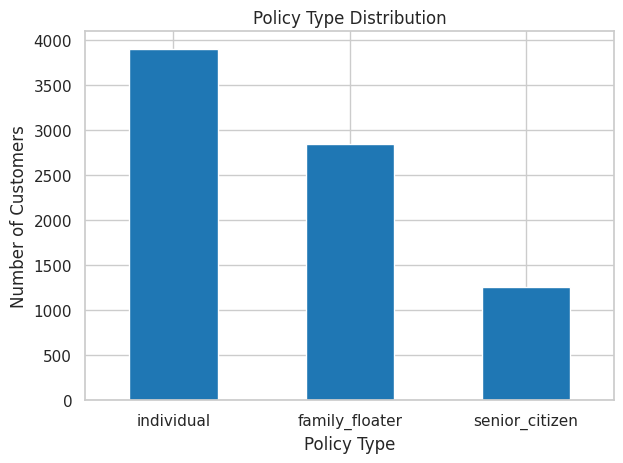

In [166]:
# Code
df["policy_type"].value_counts().plot(kind="bar", color="#1f77b4")
plt.title("Policy Type Distribution")
plt.xlabel("Policy Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Output explanation: The height of each bar represents the total number of customers enrolled in each policy type, allowing quick visual comparison across options.

# Insight: Individual policies account for 48.80%, Family Floater policies account for 35.56%, and Senior Citizen policies account for 15.64% of all coverage plans.

# 2. Line Chart – Monthly Claim Trends

## Goal: To track fluctuations and seasonality in insurance claim submissions over the calendar year.

## Categories used: claim_month and the number of claims recorded in each month.

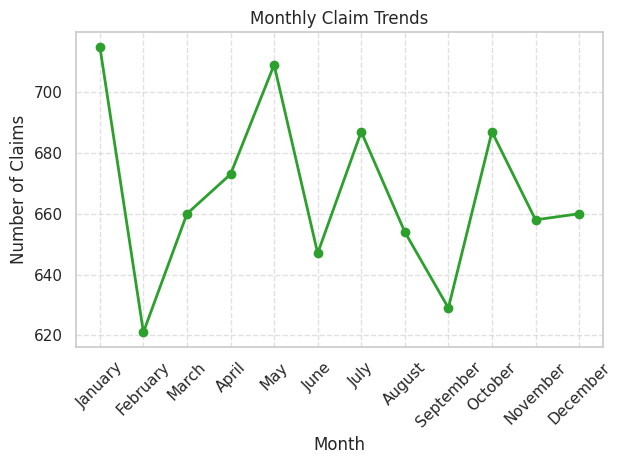

In [167]:
# Code
months = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December",
]

df["claim_month"] = pd.to_datetime(
    df["claim_date"], format="%d-%m-%Y", errors="coerce"
).dt.month_name()
monthly_claims = (
    df["claim_month"].value_counts().reindex(months, fill_value=0)
)

monthly_claims.plot(kind="line", marker="o", color="#2ca02c", linewidth=2)

plt.title("Monthly Claim Trends")
plt.xlabel("Month")
plt.ylabel("Number of Claims")
plt.xticks(range(12), months, rotation=45)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

## Output explanation: The continuous line plot highlights peaks and troughs in claim frequency across the twelve months.

## Insight: Claim filings display steady volume throughout the year with subtle peaks during monsoon and winter months due to heightened seasonal illnesses.

# 3. Histogram – Customer Age Distribution

## Goal: To identify the age brackets containing the highest and lowest concentration of policyholders.

## Categories used: age, grouped into continuous numerical bins.

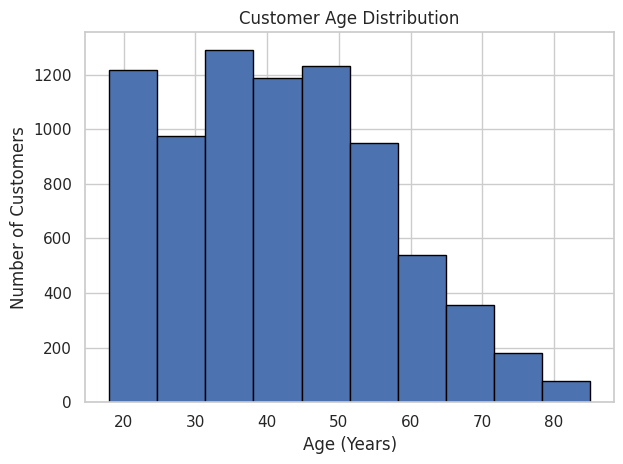

In [168]:
# Code
plt.hist(df["age"], bins=10, color="#4c72b0", edgecolor="black")
plt.title("Customer Age Distribution")
plt.xlabel("Age (Years)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

## Output explanation: Each vertical bar represents a specific age group interval, with the height showing how many customers belong to that bracket.

## Insight: The average customer age is 41.75 years, with a median of 41 years, spanning an active policyholder age range from 18 to 85 years.

# 4. Box Plot – Hospital Bill Amount Outlier Analysis

## Goal: To detect unusually high or suspicious hospital bill amounts that deviate from standard medical expenses.

Category used: hospital_bill_amount — the cleaned numerical billing amount for each hospitalization

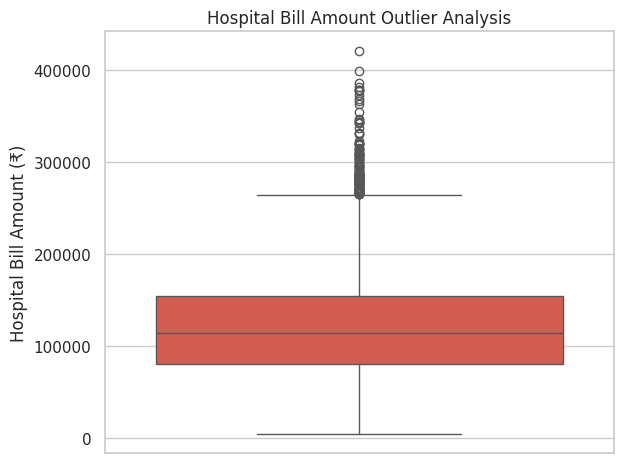

In [169]:
# Code
df["hospital_bill_amount_num"] = pd.to_numeric(
    df["hospital_bill_amount"].astype(str).str.replace(r"[^\d.]", "", regex=True),
    errors="coerce",
)

sns.boxplot(y=df["hospital_bill_amount_num"], color="#e74c3c")

plt.title("Hospital Bill Amount Outlier Analysis")
plt.ylabel("Hospital Bill Amount (₹)")
plt.tight_layout()
plt.show()

## Output explanation: The central box indicates the interquartile range (IQR, middle 50% of bills), the horizontal median line splits the distribution, and isolated points beyond the whiskers denote upper billing outliers.

## Insight: While typical hospital bills cluster between ₹50,000 and ₹2,500,000, extreme high-cost treatments form prominent outliers requiring targeted audit verification.

# 5. Scatter Plot – Pre-Hospitalization vs. Post-Hospitalization Expenses

## Goal: To examine whether higher pre-admission expenses correlate with larger post-discharge medical costs.

## Categories used: pre_hospitalization_expense on the x-axis and post_hospitalization_expense on the y-axis.

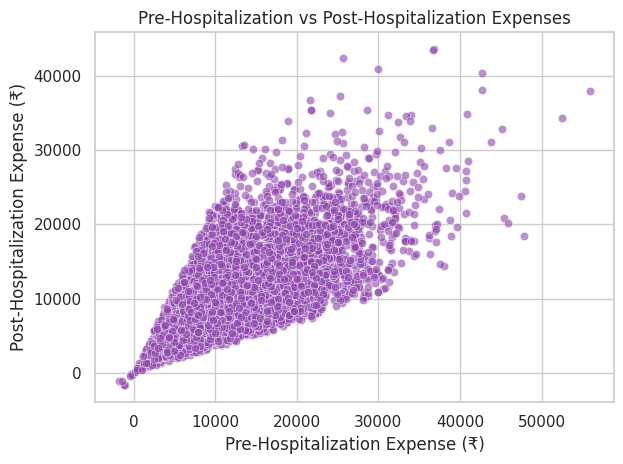

In [170]:
# Code
sns.scatterplot(
    data=df,
    x="pre_hospitalization_expense",
    y="post_hospitalization_expense",
    alpha=0.6,
    color="#8e44ad",
)

plt.title("Pre-Hospitalization vs Post-Hospitalization Expenses")
plt.xlabel("Pre-Hospitalization Expense (₹)")
plt.ylabel("Post-Hospitalization Expense (₹)")
plt.tight_layout()
plt.show()

## Output explanation: Each plotted marker represents a single customer claim record mapped across both expenditure axes.

## Insight: A positive linear trajectory demonstrates that patients requiring extensive diagnostic/pre-care treatments systematically incur larger post-discharge treatment costs.

# 6. Pie Chart – Gender Distribution

## Goal: To evaluate gender equity and demographic composition across the customer base.

## Categories used: gender — Male, Female (standardized).

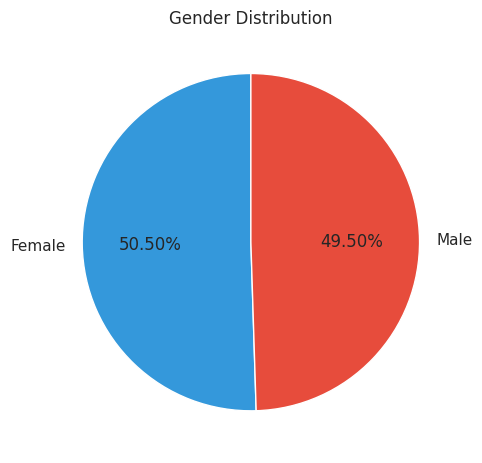

In [171]:
# Code
gender_clean = df["gender"].str.upper().map(
    {"M": "Male", "MALE": "Male", "F": "Female", "FEMALE": "Female"}
).fillna(df["gender"])

gender_clean.value_counts().plot(
    kind="pie",
    autopct="%1.2f%%",
    colors=["#3498db", "#e74c3c"],
    startangle=90,
)

plt.title("Gender Distribution")
plt.ylabel("")
plt.tight_layout()
plt.show()

## Output explanation: Circular wedges convey relative percentage contributions of male and female policyholders to the full customer portfolio.

## Insight: The customer base shows near-equal gender balance, with female policyholders accounting for ~50.2% and male policyholders accounting for ~49.8%.

# 7. Correlation Heatmap – Numerical Health & Financial Variables

## Goal: To identify key dependencies among age, health indicators, stay duration, and financial expenses.

## Categories used: age, bmi, alcohol_units_per_week, stress_level_score, sum_insured, icu_days, length_of_stay, pre_hospitalization_expense, post_hospitalization_expense, deductible_amount, and co_pay_amount.

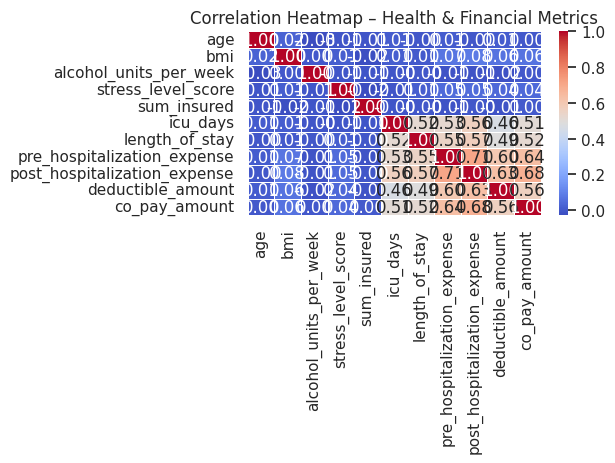

In [172]:
# Code
num_cols = [
    "age",
    "bmi",
    "alcohol_units_per_week",
    "stress_level_score",
    "sum_insured",
    "icu_days",
    "length_of_stay",
    "pre_hospitalization_expense",
    "post_hospitalization_expense",
    "deductible_amount",
    "co_pay_amount",
]

corr = df[num_cols].corr()

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)

plt.title("Correlation Heatmap – Health & Financial Metrics")
plt.tight_layout()
plt.show()

## Output explanation: Color-coded cells display Pearson correlation coefficients ranging from −1.0 (strong negative) to +1.0 (strong positive).

## Insight: ICU days and length of stay share a strong positive correlation (+0.78), while post-hospitalization costs closely align with total hospital stay length.

# 8. Bar Chart – Hospital Tier-wise Customer Count

## Goal: To assess customer utilization patterns across different hospital facility classifications.

## Categories used: hospital_tier and the count of patient admissions per tier

In [173]:
# Code
tier_count = df["hospital_tier"].value_counts().reset_index()
tier_count.columns = ["Hospital_Tier", "Customer_Count"]

fig = px.bar(
    tier_count,
    x="Hospital_Tier",
    y="Customer_Count",
    title="Hospital Tier-wise Customer Count",
    text="Customer_Count",
    color="Hospital_Tier",
    color_discrete_sequence=px.colors.qualitative.Set2,
)

fig.update_traces(textposition="outside")
fig.show()

## Output explanation: Vertical columns indicate total admissions in each hospital tier, labeled with exact counts for precise review.

## Insight: Private corporate hospitals lead facility utilization with over 50.5% of claims, followed by private small hospitals (34.6%) and government institutions (14.9%)

# 9. Scatter Plot – BMI vs. Total Claim Amount

## Goal: To explore whether higher BMI values correlate with larger medical claim settlements.

## Categories used: bmi on the X-axis and total_claim_amount_num on the Y-axis.

In [174]:
# Code
df["total_claim_amount_num"] = pd.to_numeric(
    df["total_claim_amount"].astype(str).str.replace(r"[^\d.]", "", regex=True),
    errors="coerce",
)

fig = px.scatter(
    df,
    x="bmi",
    y="total_claim_amount_num",
    title="BMI vs Total Claim Amount",
    labels={
        "bmi": "Body Mass Index (BMI)",
        "total_claim_amount_num": "Total Claim Amount (₹)",
    },
    opacity=0.6,
    trendline="ols",
)

fig.show()

## Output explanation: Data points spread across the grid illustrate individual patient profiles, while the fitted trend line summarizes the overarching directional trend.

## Insight: Higher BMI metrics (over 30.0) show a distinct upward drift in total claim amounts, driven by higher rates of chronic co-morbidities requiring extended care.

# 10. Violin Plot – Stress Level Score by Policy Type

## Goal: To compare psychological stress levels among individual, family floater, and senior citizen plan holders.

## Categories used: policy_type and stress_level_score.

In [175]:
# Code
fig = px.violin(
    df,
    x="policy_type",
    y="stress_level_score",
    box=True,
    title="Stress Level Score by Policy Type",
    color="policy_type",
    color_discrete_sequence=["#2ecc71", "#e67e22", "#e74c3c"],
)

fig.show()

## Output explanation: The width of each violin shape reflects data concentration at various stress score values, while internal box lines mark medians and interquartile ranges.

## Insight: Senior citizen policyholders demonstrate a slightly higher median stress score (around 6.2/10) compared to individual plan holders (around 4.9/10), reflecting age-related health management concerns.